# Exploratory Data Analysis: UK and US Bank Closing Prices (2015–2026)

**Project:** Bank Stock Closing Price Forecasting — Lloyds, Barclays and Goldman Sachs

This notebook uses the approved, cleaned master dataset. It performs descriptive and visual analysis without changing the source data. All cross-bank price-level comparisons use `Close_GBX` (GBX pence). Goldman Sachs' USD prices have already been converted using the approved FX procedure in the data-preparation notebook.

**Research period:** 2 January 2015 to 24 August 2026 (inclusive).

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.25})

DATA_PATH = Path("/content/all_bank_stock_data_clean.csv")
if not DATA_PATH.exists():
    # Local execution fallback; in Colab upload/copy the approved CSV to /content.
    DATA_PATH = Path("all_bank_stock_data_clean.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/all_bank_stock_data_clean.csv")
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}. Upload all_bank_stock_data_clean.csv."

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print("Loaded:", DATA_PATH, "| rows:", len(df))

Loaded: /content/all_bank_stock_data_clean.csv | rows: 8802


## 2. Dataset integrity and coverage

In [2]:
required = {"Date", "Bank", "Close_GBX"}
missing = required - set(df.columns)
assert not missing, f"Required columns missing: {missing}"

df = df.sort_values(["Bank", "Date"]).reset_index(drop=True)
assert df["Date"].notna().all()
assert df["Close_GBX"].notna().all()
assert (df["Close_GBX"] > 0).all()
assert df.duplicated(["Bank", "Date"]).sum() == 0

expected_banks = {"Barclays", "Goldman Sachs", "Lloyds"}
assert set(df["Bank"].unique()) == expected_banks, f"Unexpected bank labels: {df['Bank'].unique()}"

coverage = (df.groupby("Bank")
    .agg(Observations=("Date", "size"),
         First_Date=("Date", "min"),
         Last_Date=("Date", "max"),
         Missing_Close=("Close_GBX", lambda s: s.isna().sum()),
         Minimum_Close_GBX=("Close_GBX", "min"),
         Maximum_Close_GBX=("Close_GBX", "max"))
    .reset_index())
display(coverage.round(2))
print("Total observations:", f"{len(df):,}")
print("Overall period:", df["Date"].min().date(), "to", df["Date"].max().date())

,Bank,Observations,First_Date,Last_Date,Missing_Close,Minimum_Close_GBX,Maximum_Close_GBX
0,Barclays,2936,2015-01-02,2026-08-24,0,80.24,530.40
1,Goldman Sachs,2927,2015-01-02,2026-08-24,0,"9,583.08","86,310.78"
2,Lloyds,2939,2015-01-02,2026-08-24,0,23.98,117.10


Total observations: 8,802
Overall period: 2015-01-02 to 2026-08-24


**Interpretation:** The banks have slightly different observation counts because the London Stock Exchange and NYSE do not share identical trading calendars. The cleaned master dataset contains one observation per bank and trading date. Price comparisons below use the common GBX representation, not Goldman Sachs' original USD column.

## 3. Closing-price trends in GBX

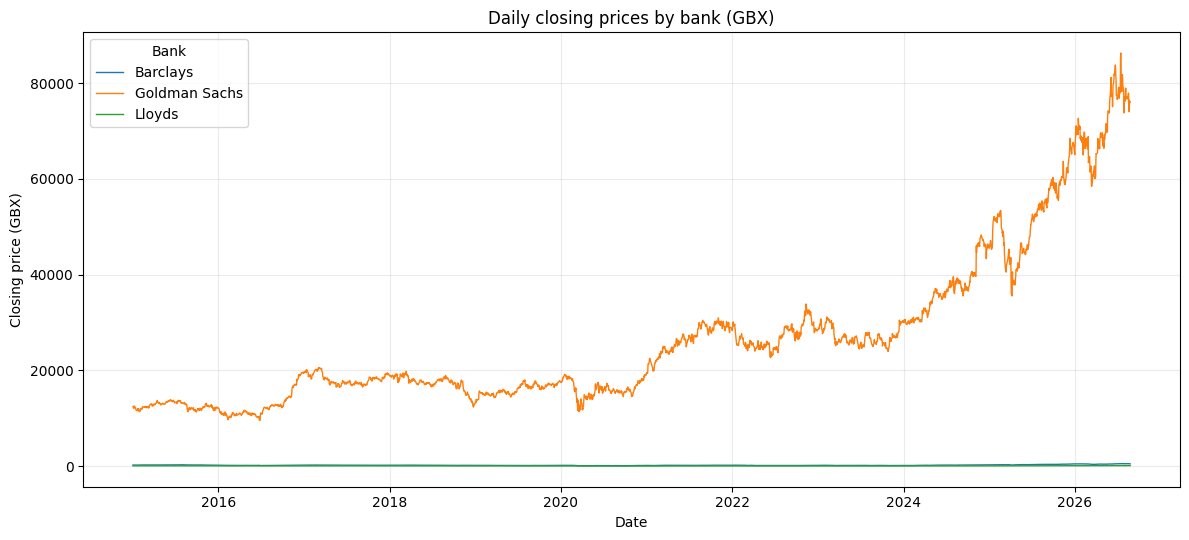

In [3]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for bank, part in df.groupby("Bank"):
    ax.plot(part["Date"], part["Close_GBX"], linewidth=1.0, label=bank)
ax.set(title="Daily closing prices by bank (GBX)", xlabel="Date", ylabel="Closing price (GBX)")
ax.legend(title="Bank")
fig.tight_layout()
plt.show()

**Interpretation:** This chart compares absolute price levels, not investment performance. Goldman Sachs has a much higher nominal share price, so its scale can visually dominate the UK banks. The chart should not be interpreted as showing which bank delivered the strongest return.

## 4. Normalised price performance (base = 100)

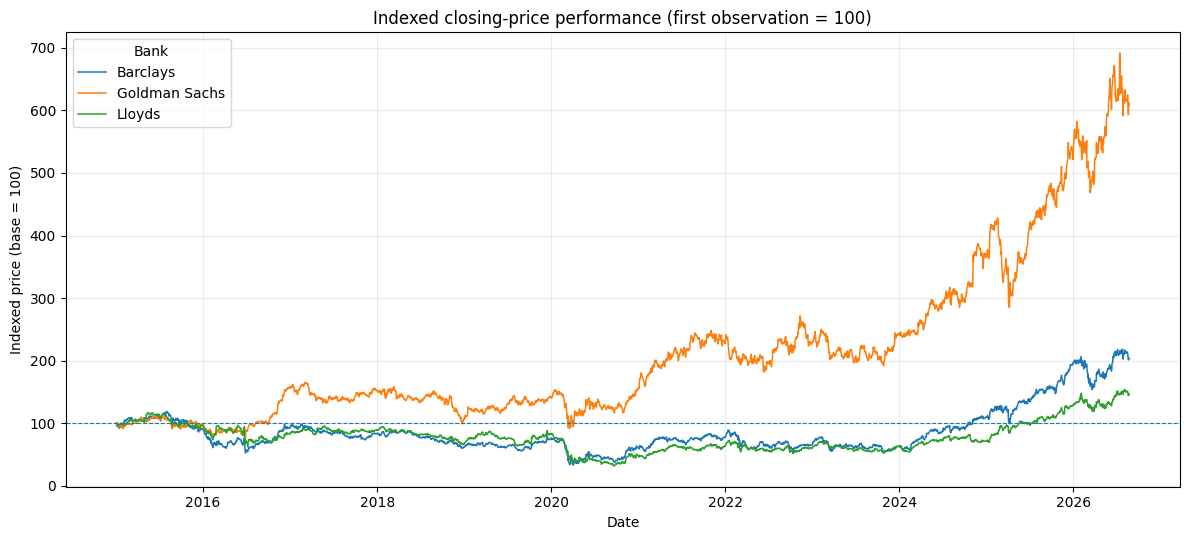

In [4]:
normalised = []
for bank, part in df.groupby("Bank", sort=False):
    part = part.sort_values("Date").copy()
    base = part["Close_GBX"].iloc[0]
    part["Indexed_Close"] = part["Close_GBX"] / base * 100
    normalised.append(part[["Date", "Bank", "Indexed_Close"]])
indexed = pd.concat(normalised, ignore_index=True)

fig, ax = plt.subplots(figsize=(12, 5.5))
for bank, part in indexed.groupby("Bank"):
    ax.plot(part["Date"], part["Indexed_Close"], linewidth=1.1, label=bank)
ax.axhline(100, linewidth=0.8, linestyle="--")
ax.set(title="Indexed closing-price performance (first observation = 100)",
       xlabel="Date", ylabel="Indexed price (base = 100)")
ax.legend(title="Bank")
fig.tight_layout()
plt.show()

**Interpretation:** Indexing puts each bank on a common starting value, making relative price appreciation and drawdowns easier to compare. It does not adjust for dividends, corporate actions beyond the source price series, or risk; it is a price-index comparison rather than total shareholder return.

## 5. Daily percentage returns

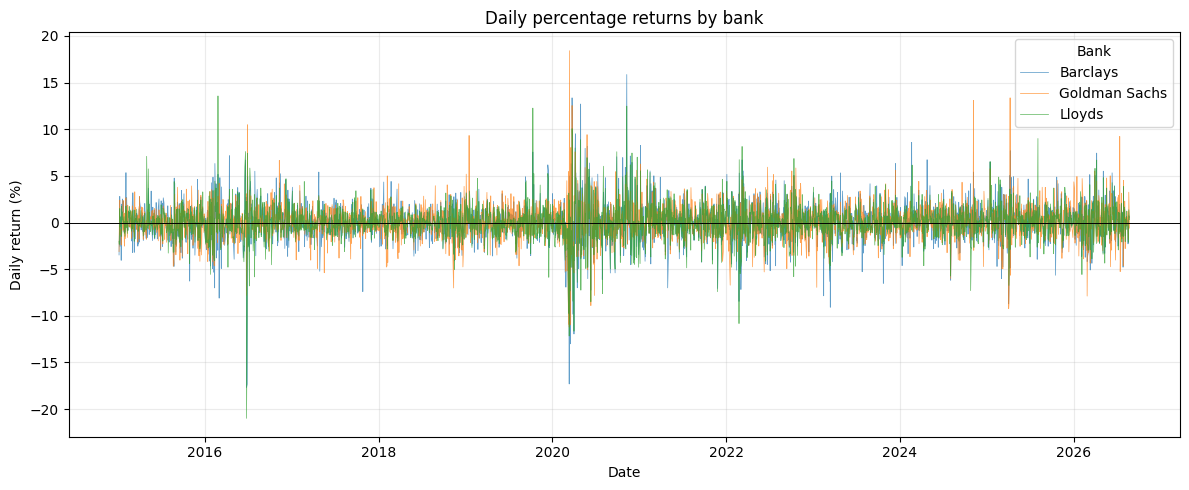

In [5]:
df["Daily_Return_pct"] = df.groupby("Bank")["Close_GBX"].pct_change(fill_method=None) * 100
returns = df.dropna(subset=["Daily_Return_pct"]).copy()

fig, ax = plt.subplots(figsize=(12, 5))
for bank, part in returns.groupby("Bank"):
    ax.plot(part["Date"], part["Daily_Return_pct"], linewidth=0.55, alpha=0.7, label=bank)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Daily percentage returns by bank", xlabel="Date", ylabel="Daily return (%)")
ax.legend(title="Bank")
fig.tight_layout()
plt.show()

**Interpretation:** Daily percentage returns focus on relative day-to-day movements rather than nominal share-price levels. Large spikes indicate unusually large daily price changes; volatility clustering can be explored further in the ARIMA residual and differenced-series diagnostics.

## 6. Distribution of daily returns

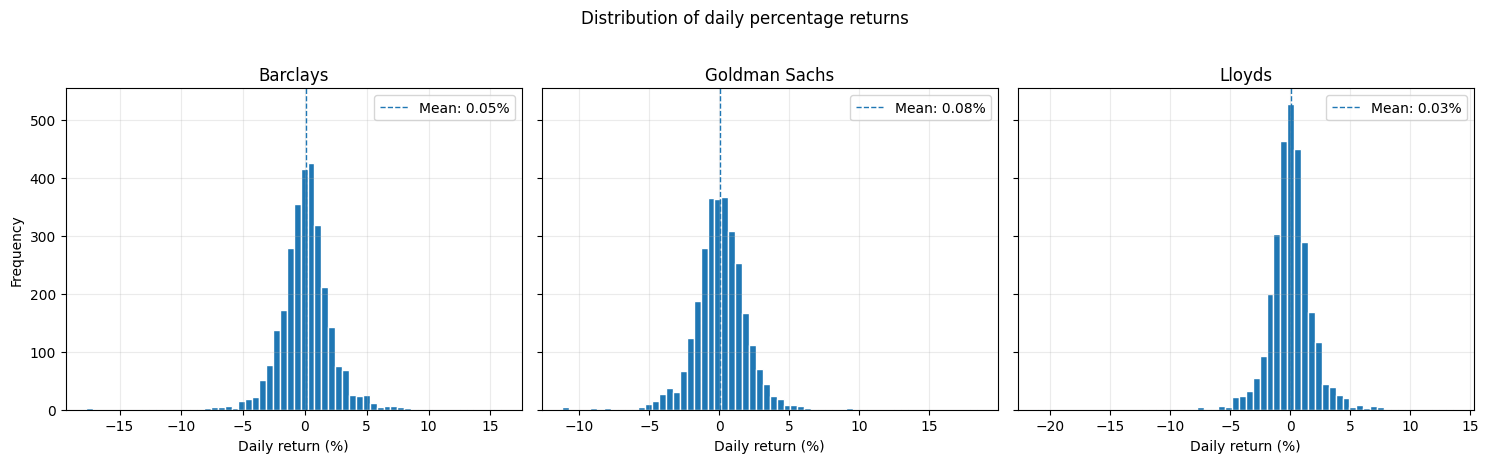

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, bank in zip(axes, sorted(returns["Bank"].unique())):
    values = returns.loc[returns["Bank"].eq(bank), "Daily_Return_pct"]
    ax.hist(values, bins=60, edgecolor="white")
    ax.axvline(values.mean(), linestyle="--", linewidth=1, label=f"Mean: {values.mean():.2f}%")
    ax.set(title=bank, xlabel="Daily return (%)")
    ax.legend()
axes[0].set_ylabel("Frequency")
fig.suptitle("Distribution of daily percentage returns", y=1.02)
fig.tight_layout()
plt.show()

**Interpretation:** Return distributions are assessed separately because each bank can have a different volatility profile. A concentration around zero with heavier tails indicates that extreme daily movements occur more often than a normal distribution would suggest. This is descriptive evidence, not a formal normality test.

## 7. Descriptive statistics

In [7]:
price_stats = (df.groupby("Bank")["Close_GBX"]
    .agg(Count="count", Mean="mean", Median="median", Std_Dev="std",
         Minimum="min", Q1=lambda s: s.quantile(0.25),
         Q3=lambda s: s.quantile(0.75), Maximum="max"))
return_stats = (returns.groupby("Bank")["Daily_Return_pct"]
    .agg(Return_Mean_pct="mean", Return_Std_pct="std",
         Return_Min_pct="min", Return_Max_pct="max"))
descriptive = price_stats.join(return_stats).reset_index()
display(descriptive.round(2))
descriptive.round(2).to_csv("eda_descriptive_statistics.csv", index=False)

,Bank,Count,Mean,Median,Std_Dev,Minimum,Q1,Q3,Maximum,Return_Mean_pct,Return_Std_pct,Return_Min_pct,Return_Max_pct
0,Barclays,2936,211.08,183.80,87.41,80.24,157.22,229.96,530.40,0.05,2.14,-17.68,15.86
1,Goldman Sachs,2927,"26,433.95","19,402.14","15,913.15","9,583.08","15,791.10","29,967.89","86,310.78",0.08,1.93,-11.21,18.42
2,Lloyds,2939,59.91,58.04,17.73,23.98,46.52,68.74,117.10,0.03,1.90,-21.00,13.57


## 8. Correlation of daily percentage returns

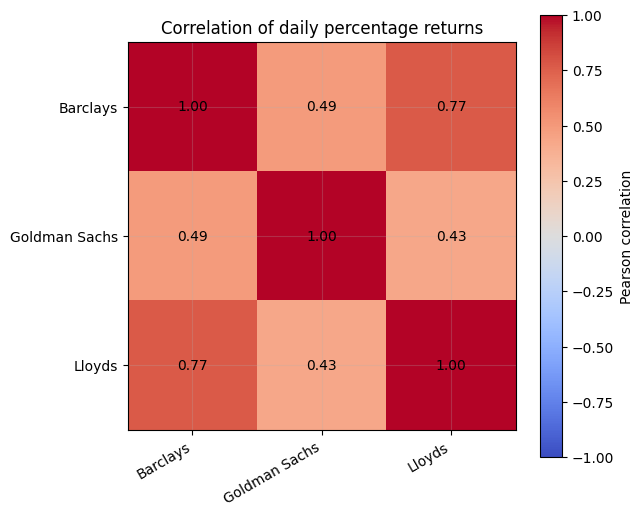

In [8]:
returns_wide = (df.pivot_table(index="Date", columns="Bank", values="Close_GBX", aggfunc="last")
    .sort_index().pct_change(fill_method=None))
return_corr = returns_wide.corr(min_periods=100)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(return_corr.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(return_corr.columns)))
ax.set_xticklabels(return_corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(return_corr.index)))
ax.set_yticklabels(return_corr.index)
for i in range(len(return_corr.index)):
    for j in range(len(return_corr.columns)):
        ax.text(j, i, f"{return_corr.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Correlation of daily percentage returns")
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()
return_corr.round(2).to_csv("eda_daily_return_correlation.csv")

**Interpretation:** This is a correlation matrix of daily percentage returns, not raw price levels or engineered model features. It therefore describes co-movement in daily returns and avoids the misleading high correlations that can arise simply because unrelated price series trend upward over time. Correlation does not imply causation.

## 9. Trading volume (where available)

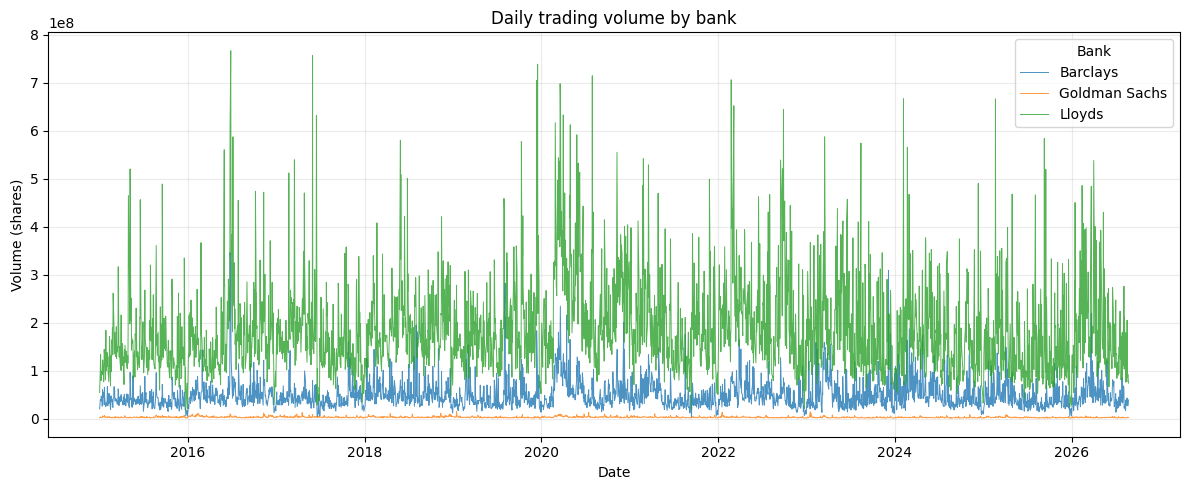

,count,mean,median,min,max
Bank,,,,,
Barclays,2936,"49,004,952.20","41,413,717.00",1549882,345720341
Goldman Sachs,2927,"2,833,901.84","2,503,700.00",460100,15194200
Lloyds,2939,"186,672,883.52","163,908,543.00",18116240,766905666


In [9]:
if "Volume" in df.columns:
    fig, ax = plt.subplots(figsize=(12, 5))
    for bank, part in df.groupby("Bank"):
        ax.plot(part["Date"], part["Volume"], linewidth=0.7, alpha=0.8, label=bank)
    ax.set(title="Daily trading volume by bank", xlabel="Date", ylabel="Volume (shares)")
    ax.legend(title="Bank")
    fig.tight_layout()
    plt.show()
    volume_stats = df.groupby("Bank")["Volume"].agg(["count", "mean", "median", "min", "max"]).round(2)
    display(volume_stats)
else:
    print("Volume column not present; volume analysis skipped.")

## 10. Export analysis dataset and audit summary

In [10]:
# Export only derived descriptive outputs; the approved cleaned source dataset is not overwritten.
returns[["Date", "Bank", "Close_GBX", "Daily_Return_pct"]].to_csv("eda_daily_returns.csv", index=False)
print("Saved:")
print("- eda_descriptive_statistics.csv")
print("- eda_daily_return_correlation.csv")
print("- eda_daily_returns.csv")
print("Source dataset unchanged:", DATA_PATH)

Saved:
- eda_descriptive_statistics.csv
- eda_daily_return_correlation.csv
- eda_daily_returns.csv
Source dataset unchanged: /content/all_bank_stock_data_clean.csv


## EDA conclusions for the report

Use the actual figures and statistics generated above when writing the report. The EDA supports four main descriptive points:

1. Absolute GBX closing prices differ substantially across banks, so indexed prices and percentage returns are more useful for relative comparisons.
2. The banks have different trading calendars and observation counts.
3. Daily returns fluctuate around zero and can contain large movements; volatility should not be inferred from price-level plots alone.
4. Cross-bank correlation is calculated on daily percentage returns rather than raw price levels or engineered features.

**Important:** Do not describe the indexed series as dividend-adjusted total returns. Do not claim that correlation establishes causation. Keep the source data and approved scraping/preprocessing notebook unchanged.